# Leading eigenvectors of G(x)

* **Author**: laquitainesteeve@gmail.com
* **Purpose**: 
    * Plot an object image with the receptive fields of two neural models (of monkey areas V1 and V4), and the leading eigenvectors of G(x) for these neural model (as in Fig. 3D–F of the paper).
    * Compare to Fisher Information J(x)'s leading eigenvectors.
* **Tested on**: Ubuntu 24.04.1 LTS (32 cores, 188 GB RAM, Intel(R) Core(TM) i9-14900K ＠3.2 GHz/5.8 GHz); RTX590 GPU (40GB VRAM)
* **Execution time**: 

## 1. Setup Jupyter kernel

```bash
# Setup the python environment and the jupyter kernel from the repository root (see README.md)
conda env create -f environment.yml --prefix ./env     # (1 min)
conda activate ./env
pip install "multigeom[all]"                           # or, from a clone of the package: pip install -e "<path-to>/MultiscaleInformationGeometry[all]"
python -m ipykernel install --user --name multigeom --display-name "multigeom"
```


## 2. Download datasets

The pipeline reads three external datasets. Download each from its source, format them and place it under `data/` with this layout:

```
data/
├── tvsd/
│   ├── monkeyN_THINGS_normMUA.mat
│   └── things_imgs.mat
├── things_images/
│   └── object_images/<concept>/<image>.jpg
└── tiny-imagenet-200/
    ├── train/<wnid>/images/<image>.JPEG
    └── val/images/<image>.JPEG
```

* Download TSVD data from g-node:

```bash
bash notebooks/download_tsvd_data.sh # (15 secs, 196MB)
```

* Download things images from osf:

```bash
bash notebooks/download_things_images.sh # (2 min, 4.9GB)
```

* Download tiny-imagenet images from Stanford.edu:

```bash
bash notebooks/download_tiny_imagenet.sh # (50 secs, 481MB)
```

note: Set NEURIPS_DATA_DIR=/path/to/storage to read the datasets from elsewhere



## 3. Download trained encoders & diffusion models

### 3.1. Encoders' backbone

1. **InceptionV3**: The neural encoders' pretrained weights are downloaded by torchvision on first use (cached under $TORCH_HOME).

2. **ResNet-50 ImageNet**: IDEM

3. **Berardino et al. (2017)**: Their ON-OFF front-end ships with plenoptic (OnOff(pretrained=True)); nothing to download by hand.

### 3.2 Encoders' readout and diffusion weights



* The checkpoints are neural encoders fitted to the neural data we downloaded. The only part that was fitted is a small readout on top of the torchvision weights.

```
runs/
├── diffusion/
│   └── inception
│       └── V1
│           └── final_model.pt
│       └── V4
            └── final_model.pt
│   └── resnet50
│       └── V1
│           └── final_model.pt
│       └── V4
            └── final_model.pt
├── encoders/
│   ├── inception
│       └── V1
│           └── final_model.pt
│       └── V4
            └── final_model.pt
│   └── resnet50
│       └── V1
│           └── final_model.pt
│       └── V4
            └── final_model.pt
```

* Download the weights in `runs/`

```bash
huggingface-cli download steevelaquitaine/multigeom --local-dir runs
```

## 4. Import packages

We use the models checkpoints in `runs/`.

In [ ]:
# import built-in packages 
import os, sys, subprocess
from pathlib import Path
import torch
import copy, time
import matplotlib.pyplot as plt
from PIL import Image

# move to the repository root (the folder containing environment.yml): data/ and runs/ are read from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent
os.chdir(root)
print("repo root:", root)

# import custom package
from multigeom import estimate_g, compute_fisher
from multigeom.config import load_config
from multigeom.utils import get_device, make_generator
from multigeom.data import TinyImageNetDataset, CANONICAL_TRANSFORM
from multigeom.encoders import build_encoder
from multigeom.diffusion.model import build_diffusion_model, build_scheduler
from multigeom.viz.fig3 import panel_rf, panel_eigvecs
from multigeom.viz.fig4 import panel_eigvecs as panel_eigvecs_fig4
from multigeom.viz.style import panel_label

# choose an encoder (and area) to load in section 5, and the encoders to compare in section 6
ENC, AREA = "inception", "V1"
ENCODERS = ["inception", "resnet50"]      # onoff checkpoints are not available
AREAS = ["V1", "V4"]

# load the encoder, diffusion and estimator configs (packaged with multigeom)
enc_cfg = load_config(ENC)
diff_cfg = load_config("diffusion")
est_cfg = load_config("estimator")

# choose the image for which to estimate G(x) and J(x): the example image of paper Fig. 3D
# (first TinyImageNet *training* image of the class n01644900, a frog)
IMG_PATH = "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG"
N_MC = 50   # (default: 200) number of monte carlo samples                    

# compute device
device = get_device(None)
print("device:", device)

## 5. Load one model pair

Encoder f_φ (frozen backbone + fitted readout) and the conditional diffusion model ε_θ, here for **inception / V1**. Change `ENC` and `AREA` to look at another configuration.

In [26]:
%%time 

# encoder
encoder = build_encoder(enc_cfg).to(device)
encoder.load_state_dict(torch.load(f"runs/encoders/{ENC}/{AREA}/best_model.pt", map_location=device, weights_only=False)["model_state_dict"])
encoder.eval()

# diffusion model
unet = build_diffusion_model(diff_cfg).to(device)
diff_ckpt = torch.load(f"runs/diffusion/{ENC}/{AREA}/final_model.pt", map_location=device, weights_only=False)
unet.load_state_dict(diff_ckpt["model_state_dict"])
unet.eval()
scheduler = build_scheduler(diff_cfg)
alphas_cumprod = scheduler.alphas_cumprod.to(device)

# report info
print("diffusion epoch:", diff_ckpt.get("epoch"))

diffusion epoch: 120
CPU times: user 9.09 s, sys: 85.1 ms, total: 9.18 s
Wall time: 1.19 s


## 6. Estimate G(x) and J(x), and plot paper Fig. 3D-F and Fig. 4B-C

Estimate the top eigenpairs of the multi-scale Fisher metric G(x) (conditional-pair estimator, Algorithm 1) and of the closed-form Fisher metric J(x) for the example image of Fig. 3D, for each encoder (inception, resnet50) fitted to V1 and to V4. Then plot:

* **Fig. 3D-F** (inception): the image with the V1 and V4 receptive fields (D), and the leading four eigenvectors of G (E) and of J (F), V1 on top and V4 below.
* **Fig. 4B-C** (inception and resnet50): the leading eigenvectors of G (B) and of J (C) for each architecture, V1 block above the V4 block. The paper also shows the ON-OFF model, which we have no checkpoints for (empty rows).

with the plotting functions of `multigeom.viz.fig3` and `multigeom.viz.fig4`.

`N_MC` is the number of Monte-Carlo samples. The paper uses 200 (about 15 s per image, encoder and area on this GPU); use a smaller value for a quick look. Results from these cells are not saved.

#### 6.1 Compute

* **execution time**: about 12 secs with `N_MC = 50` (about 1 min with 200)

In [ ]:
%%time 

cfg = copy.deepcopy(est_cfg)
cfg.monte_carlo.n_samples = N_MC
sigma = float(cfg.monte_carlo.observation_noise_sigma)

x = CANONICAL_TRANSFORM(Image.open(IMG_PATH)).unsqueeze(0).to(device)   # [1, 1, 64, 64] in [-1, 1]

ckpts, records = {}, {}      # keyed by (encoder, area): encoder checkpoint, and the image + eigenpairs of G and J
for enc_name in ENCODERS:
    for area in AREAS:
        # encoder and diffusion model fitted to this area
        ckpts[(enc_name, area)] = torch.load(f"runs/encoders/{enc_name}/{area}/best_model.pt", map_location="cpu", weights_only=False)
        area_encoder = build_encoder(load_config(enc_name)).to(device)
        area_encoder.load_state_dict(ckpts[(enc_name, area)]["model_state_dict"])
        area_encoder.eval()
        area_unet = build_diffusion_model(diff_cfg).to(device)
        area_unet.load_state_dict(torch.load(f"runs/diffusion/{enc_name}/{area}/final_model.pt", map_location=device, weights_only=False)["model_state_dict"])
        area_unet.eval()

        # G(x) (conditional-pair estimator) and J(x) (closed form)
        g = estimate_g(image=x, encoder=area_encoder, unet=area_unet, alphas_cumprod=alphas_cumprod,
                       cfg=cfg, device=device, generator=make_generator(int(cfg.seed), device))
        j = compute_fisher(image=x, encoder=area_encoder, sigma=sigma, top_k=int(cfg.fisher_baseline.top_k), device=device)
        records[(enc_name, area)] = {"image": x.cpu(),
                                     "G_eigenvalues": g.eigenvalues.cpu(), "G_eigenvectors": g.eigenvectors.cpu(),
                                     "J_eigenvalues": j.eigenvalues.cpu(), "J_eigenvectors": j.eigenvectors.cpu()}
        print(enc_name, area, "G:", tuple(g.eigenvectors.shape), " J:", tuple(j.eigenvectors.shape))

#### 6.2. Plot leading eigenvectors for inception

*  cf. Fig. 3D-F
* The diffusion checkpoints report epoch 120, not the 200 used for the paper. 
* Monte carlo noise of the G(x) estimator: seed 42.
* The encoder weight checkpoint may differ from what the paper's.
* execution time: < 1 sec

CPU times: user 2.19 s, sys: 3.14 ms, total: 2.19 s
Wall time: 272 ms


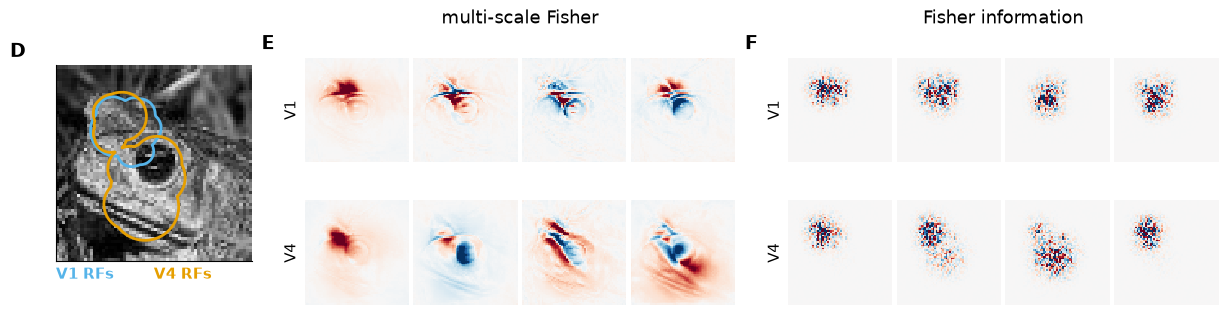

In [28]:
%%time 

fig = plt.figure(figsize=(15, 3.9))
spec = fig.add_gridspec(1, 3, width_ratios=[1.0, 2.2, 2.2], wspace=0.15)
ax_d = fig.add_subplot(spec[0])
panel_rf(ax_d, records[(ENC, "V1")]["image"], {a: ckpts[(ENC, a)] for a in AREAS})                   # D: image with V1 and V4 receptive fields
ax_e = panel_eigvecs(fig, spec[1], {a: records[(ENC, a)] for a in AREAS}, "G", 4)             # E: leading eigenvectors of G(x)
ax_f = panel_eigvecs(fig, spec[2], {a: records[(ENC, a)] for a in AREAS}, "J", 4)             # F: leading eigenvectors of J(x)
for letter, ax in zip("DEF", (ax_d, ax_e, ax_f)):
    panel_label(fig, ax, letter)
fig

#### 6.3. Plot comparison inception vs resnet50

* cf. paper's Fig. 4B-C

* execution time: < 1 sec
* For resnet50 (and ON-OFF), each displayed eigenvector is the one, among its first 30, that best matches (largest |cosine|) the inception eigenvector of the same column, with its sign flipped to agree. This only changes what is displayed.

CPU times: user 4.26 s, sys: 3.05 ms, total: 4.26 s
Wall time: 454 ms


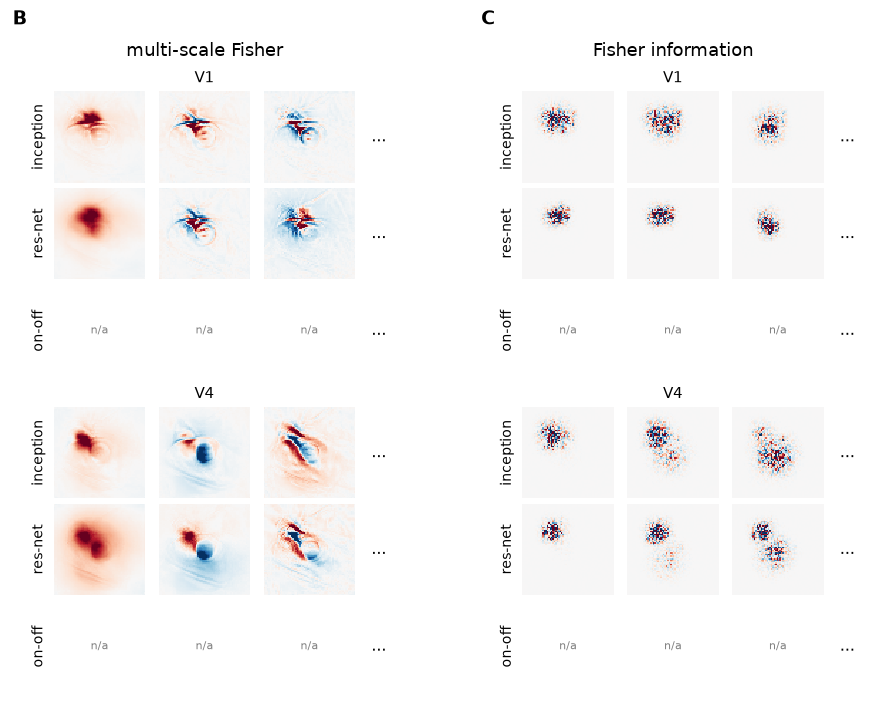

In [29]:
%%time 

fig = plt.figure(figsize=(11, 8.5))
spec = fig.add_gridspec(1, 2, wspace=0.22)
ax_b = panel_eigvecs_fig4(fig, spec[0], records, "G", 3, 30)    # B: leading eigenvectors of G(x), per encoder
ax_c = panel_eigvecs_fig4(fig, spec[1], records, "J", 3, 30)    # C: leading eigenvectors of J(x), per encoder
for letter, ax in zip("BC", (ax_b, ax_c)):
    panel_label(fig, ax, letter)
fig